Benjamin Arnold; 10/18/2026; Lab 7: Physics Engine

Part A-- Core Engine

--------------------DIAGRAM-----------------------
1. WORLD
    PURELY FORMAL: ESTABLISHES RELATION BETWEEN FORCES, BODIES, AND THE INTEGRATOR
2. INTEGRATOR
    RESOLVES AND UPDATES: TAKES THE STATES OF BODIES AND THE TOTAL FORCES ACTING ON THEM TO TIME-STEP, ALSO RESOLVES COLLISIONS.
3. FORCES
    RELATES BODIES: MODIFIES THE STATE OF BODIES
4. BODIES
    THINGS: THEY HAVE PHYSICAL STATES

A.1: Body

In [1]:
import numpy as np

class Body:
    def __init__(self, m=1.0, r=(0.0, 0.0), v=(0.0, 0.0), radius=0.0,
                    fixed=False, name=""):
        self.m, self.radius = float(m), float(radius)
        self.fixed = bool(fixed)
        self.name = name
        
        self.r = np.array(r, dtype=float)
        self.v = np.array(v, dtype=float)
        self.f = np.zeros(2)

    @property
    def inv_m(self):
        return 0.0 if self.fixed else 1.0 / self.m

    def clear(self):
        self.f[:] = 0.0

    def add_force(self, F):
        self.f += np.asarray(F, dtype=float)

    def ke(self):
        return 0.5 * self.m * self.v.dot(self.v)

    def p(self):
        return self.m * self.v

    def __repr__(self):
        return f"Body({self.name}, m={self.m}, r={self.r}, v={self.v})"

A.2: Force

In [2]:
class Force:
    def potential_energy(self, world):
        return 0.0

class Gravity(Force):
    def __init__(self, g=9.81):
        self.gmag = g
        self.g    = np.array([0.0, -g])

    def apply(self, world):
        for b in world.bodies:
            if not b.fixed:
                b.add_force(b.m * self.g)

    def potential_energy(self, world):
        return sum(b.m * self.gmag * b.r[1] for b in world.bodies if not b.fixed)

class Spring(Force):
    def __init__(self, i, j, k=1.0, L0=0.0):
        self.i, self.j, self.k, self.L0 = i, j, k, L0

    def length(self, world):
        a, b = world.bodies[self.i], world.bodies[self.j]
        d = b.r - a.r
        return a, b, d, np.linalg.norm(d)
    
    def apply(self, world):
        a, b, d, L = self.length(world)
        if L > 0:
            F = self.k * (L - self.L0) * (d / L)
            a.add_force(F)
            b.add_force(-F)

    def potential_energy(self, world):
        _, _, _, L = self.length(world)
        return 0.5 * self.k * (L - self.L0)**2

class Drag(Force):
    def __init__(self, k=0.1, n=1.0):
        self.k, self.n = k, n
        
    def apply(self, world):
        for b in world.bodies:
            if b.fixed:
                continue
            vmag = np.linalg.norm(b.v)
            if vmag == 0:
                continue
            b.add_force(-self.k*(vmag**self.n)*b.v)

A.3: Integrator

In [3]:
class EulerCromer:
    name= "Euler Cromer"
    def step(self, world, dt):
        world.compute_forces()
        for b in world.bodies:
            if b.fixed:
                continue
            b.v += (b.f*b.inv_m)*dt
            b.r += b.v*dt

class Euler:
    name = "Euler"
    def step(self, world, dt):
        world.compute_forces()
        for b in world.bodies:
            if b.fixed:
                continue
            a = b.f * b.inv_m
            b.r     += b.v * dt 
            b.v     += a * dt

A.4: World

In [4]:
class World:
    def __init__(self, integrator=None, forces=None, bodies=None, constraints=None):
        self.bodies      = list(bodies or [])
        self.forces      = list(forces or [])
        self.constraints = list(constraints or [])
        self.integrator  = integrator
        self.t           = 0.0
        self.recorders   = {}
        self.history     = {}

    def add(self, body):
        self.bodies.append(body); return body

    def add_force(self, force):
        self.forces.append(force); return force

    def add_constraint(self, c):
        self.constraints.append(c); return c

    def compute_forces(self):
        for b in self.bodies:
            b.clear()
        for f in self.forces:
            f.apply(self)                  

    def step(self, dt):
        self.integrator.step(self, dt)      
        for c in self.constraints:          
            c.resolve(self)
        self.t += dt                              

    
    def kinetic_energy(self):
        return sum(b.ke() for b in self.bodies)
    def potential_energy(self):
        return sum(f.potential_energy(self) for f in self.forces)
    def total_energy(self):
        return self.kinetic_energy() + self.potential_energy()
    def momentum(self):
        return sum((b.p() for b in self.bodies), np.zeros(2))

    
    def record(self, name, fn):
        self.recorders[name] = fn
        self.history[name]   = []

    def capture(self):
        for k, fn in self.recorders.items():
            self.history[k].append(fn(self))

    def run(self, dt, t_end):
        self.capture()
        for _ in range(int(round(t_end / dt))):
            self.step(dt)
            self.capture()
        return {k: np.array(v) for k, v in self.history.items()}

A.5: Constraints

In [5]:
def resolve_pair(a, b, e=1.0):
    d    = b.r - a.r
    dist = np.linalg.norm(d)
    if dist == 0 or dist > a.radius + b.radius:
        return False                      

    n     = d / dist                      
    v_rel = b.v - a.v
    vn    = v_rel.dot(n)
    if vn > 0:
        return False                     

    im_a, im_b = a.inv_m, b.inv_m
    if im_a + im_b == 0:
        return False                      

    J = -(1 + e) * vn / (im_a + im_b)    
    a.v -= J * im_a * n
    b.v += J * im_b * n

    overlap = a.radius + b.radius - dist  
    a.r -= n * overlap * (im_a / (im_a + im_b))
    b.r += n * overlap * (im_b / (im_a + im_b))
    return True


class CircleCollisions:
    def __init__(self, e=1.0):
        self.e = e
        self.count = 0
    def resolve(self, world):
        bs = world.bodies
        for i in range(len(bs)):
            for j in range(i + 1, len(bs)):
                if bs[i].radius > 0 and bs[j].radius > 0:
                    if resolve_pair(bs[i], bs[j], self.e):
                        self.count += 1


class BoxWalls:
    def __init__(self, xmin, xmax, ymin, ymax, e=1.0):
        self.bounds = (xmin, xmax, ymin, ymax)
        self.e = e
        self.count = 0
    def resolve(self, world):
        xmin, xmax, ymin, ymax = self.bounds
        for b in world.bodies:
            if b.fixed:
                continue
            R = b.radius
            if b.r[0] - R < xmin:
                b.r[0] = xmin + R; b.v[0] = -self.e * b.v[0]; self.count += 1
            if b.r[0] + R > xmax:
                b.r[0] = xmax - R; b.v[0] = -self.e * b.v[0]; self.count += 1
            if b.r[1] - R < ymin:
                b.r[1] = ymin + R; b.v[1] = -self.e * b.v[1]; self.count += 1
            if b.r[1] + R > ymax:
                b.r[1] = ymax - R; b.v[1] = -self.e * b.v[1]; self.count += 1

Part B-- Validation Against Old Labs

B.1: Lab 1-- Projectile Motion

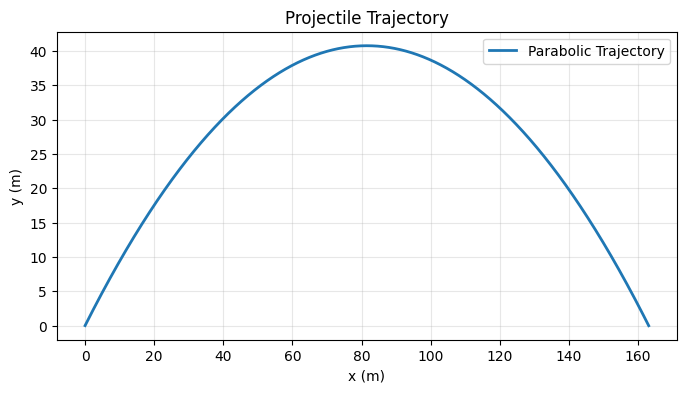

v0 = 40 m/s, 45 degrees
  E0                = 800.00 J
  max|dE|/E0        = 3.468e-04
  range (simulated) = 163.0871 m
  range (theory)    = 163.0989 m


In [6]:
import matplotlib.pyplot as plt

world=World(integrator=EulerCromer())
world.add_force(Gravity())

theta, v0=np.pi/4, 40
proj=Body(v=[v0*np.cos(theta),v0*np.sin(theta)])
world.add(proj)

world.record('t', lambda W: W.t)
world.record('x', lambda W: W.bodies[0].r[0])
world.record('y', lambda W: W.bodies[0].r[1])
world.record('E', lambda W: W.total_energy())

w=world.run(dt=0.001,t_end=2*v0*np.sin(theta)/9.81)
x,y,E=w['x'],w['y'],w['E']

plt.figure(figsize=(8, 4))
plt.plot(x, y, linewidth=2, label='Parabolic Trajectory')
plt.xlabel('x (m)')
plt.ylabel('y (m)')
plt.title('Projectile Trajectory')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

print("v0 = 40 m/s, 45 degrees")
print(f"  E0                = {E[0]:.2f} J")
print(f"  max|dE|/E0        = {np.max(np.abs(E-E[0]))/abs(E[0]):.3e}")
print(f"  range (simulated) = {x[-1]:.4f} m")
print(f"  range (theory)    = {v0**2*np.sin(2*theta)/9.81:.4f} m")

B.2: Lab 3-- Oscillator

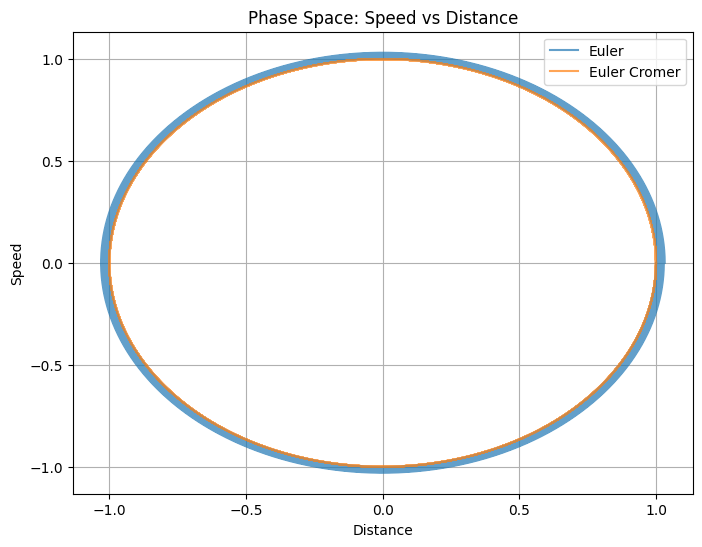

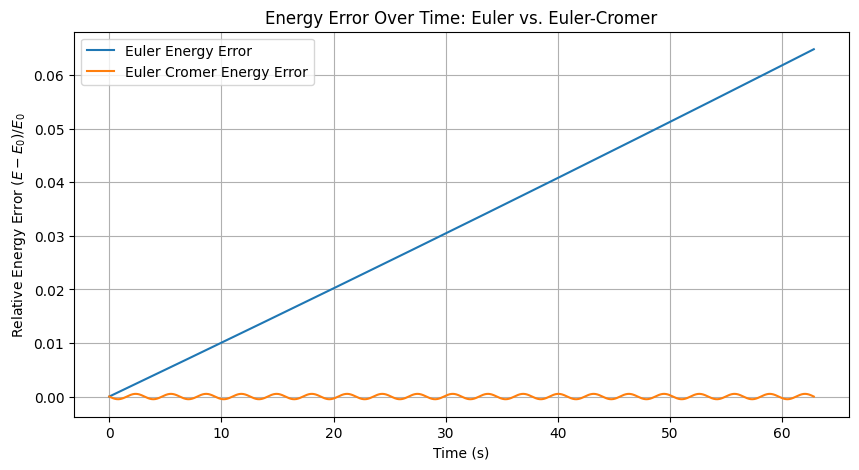

In [7]:
T=2*np.pi
result={}
for I in (Euler, EulerCromer):
    world=World(integrator=I())
    world.add(Body(m=1.0, r=(0, 0), fixed=True))
    world.add(Body(m=1.0, r=(1, 0), v=(0, 0)))
    world.add_force(Spring(0,1))

    world.record('t', lambda W: W.t)
    world.record('x', lambda W: W.bodies[1].r[0])
    world.record('v', lambda W: W.bodies[1].v[0])
    world.record('E', lambda W: W.total_energy())

    w=world.run(dt=0.001,t_end=10*T)

    x = np.array(world.history['x'])
    t = np.array(world.history['t'])
    v = np.array(world.history['v'])
    E = np.array(world.history['E'])

    name=I.name
    result[name] = {
        'distance': x,
        'time': t,
        'speed': v,
        'energy': E
    }

plt.figure(figsize=(8, 6))
for name, data in result.items():
    plt.plot(data['distance'], data['speed'], label=name, alpha=0.7)
plt.title('Phase Space: Speed vs Distance')
plt.xlabel('Distance')
plt.ylabel('Speed')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 5))
for name, data in result.items():
    relative_energy_error = (data['energy'] - data['energy'][0]) / data['energy'][0]
    plt.plot(data['time'], relative_energy_error, label=f"{name} Energy Error")
plt.title('Energy Error Over Time: Euler vs. Euler-Cromer')
plt.xlabel('Time (s)')
plt.ylabel('Relative Energy Error $(E - E_0) / E_0$')
plt.legend()
plt.grid(True)
plt.show()

B.3: Lab 4 Collisions

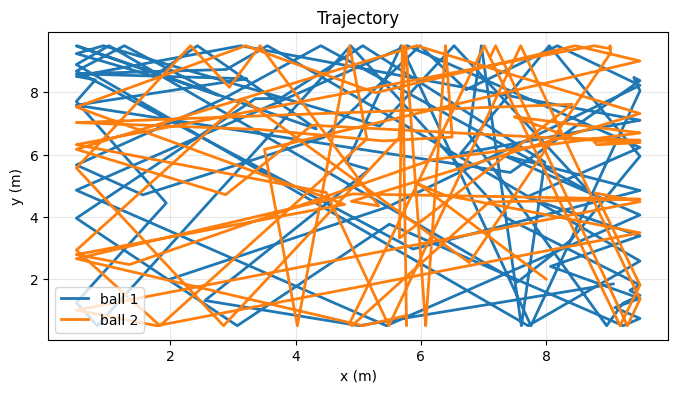

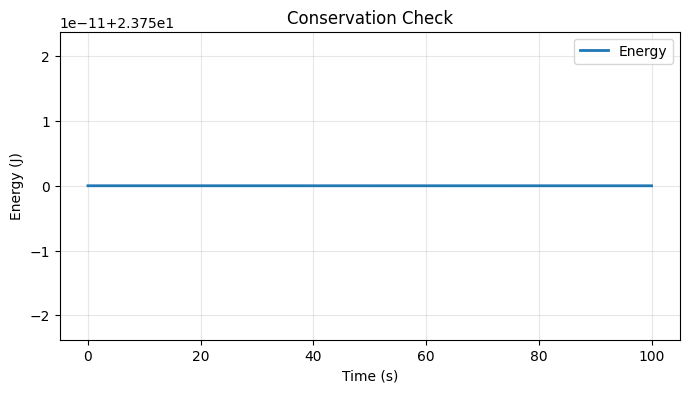

In [8]:
def collision_scene(e, walls=True):
    coll = CircleCollisions(e=e)
    cons = [coll]
    wl   = BoxWalls(0, 10, 0, 10, e=1.0) if walls else None
    if wl: cons.append(wl)
    w = World(integrator=EulerCromer(), constraints=cons)
    for p, v in zip([(2,2), (8,2), (2,8), (8,8)],
                    [(3,2), (-2,3), (2.5,-1.5), (-3,-2)]):
        w.add(Body(m=1.0, r=p, v=v, radius=0.5))
    return w, coll, wl

world, coll, wl = collision_scene(e=1.0, walls=True)

world.record('t', lambda W: W.t)
world.record('r1', lambda W: np.array(W.bodies[0].r))
world.record('r2', lambda W: np.array(W.bodies[1].r))
world.record('E', lambda W: np.array(W.total_energy()))

w=world.run(dt=0.001,t_end=100)

t = np.array(world.history['t'])
E = np.array(world.history['E'])
r1 = np.array(world.history['r1'])
r2 = np.array(world.history['r2'])


plt.figure(figsize=(8, 4))
plt.plot(r1[:,0], r1[:,1], linewidth=2, label='ball 1')
plt.plot(r2[:,0], r2[:,1], linewidth=2, label='ball 2')
plt.xlabel('x (m)')
plt.ylabel('y (m)')
plt.title('Trajectory')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(t, E, linewidth=2, label='Energy')
plt.xlabel('Time (s)')
plt.ylabel('Energy (J)')
plt.title('Conservation Check')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

Part C: Multi-Body Scene

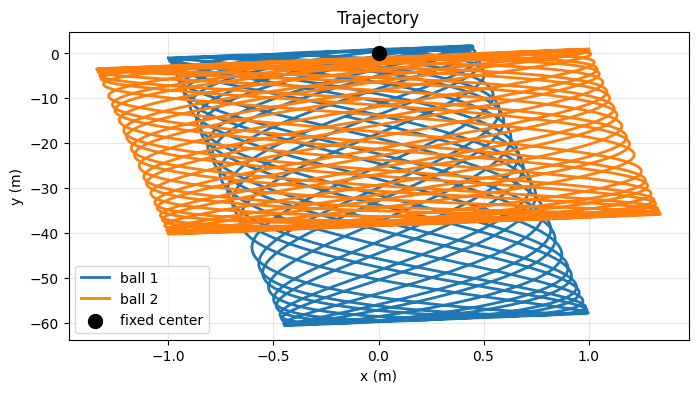

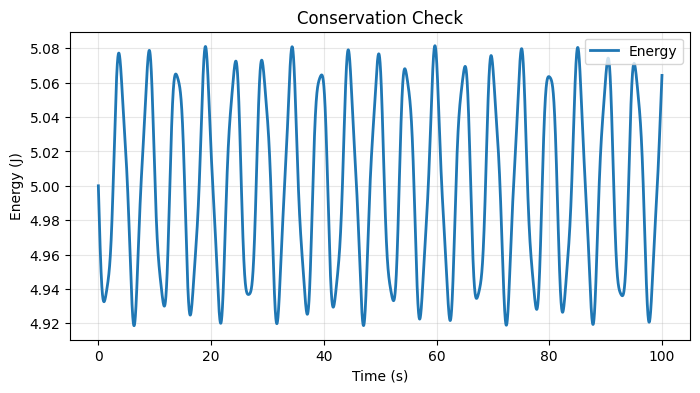

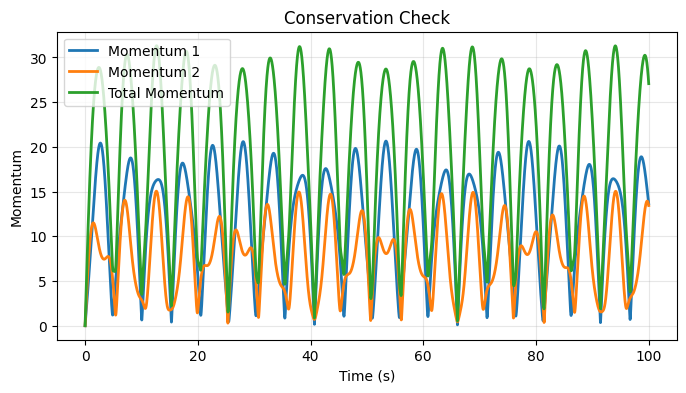

In [9]:
world=World(integrator=EulerCromer())
world.add(Body(m=1.0, r=(-1, -1), v=(0,0)))
world.add(Body(m=1.0, r=(1, 1), v=(0,0)))
world.add(Body(m=1.0, r=(0, 0), fixed=True))
world.add_force(Spring(0,1))
world.add_force(Spring(1,2))
world.add_force(Gravity())

world.record('t', lambda W: W.t)
world.record('r1', lambda W: np.array(W.bodies[0].r))
world.record('r2', lambda W: np.array(W.bodies[1].r))
world.record('v1', lambda W: np.array(W.bodies[0].v))
world.record('v2', lambda W: np.array(W.bodies[1].v))
world.record('E', lambda W: np.array(W.total_energy()))

w=world.run(dt=0.001,t_end=100)

t = np.array(world.history['t'])
E = np.array(world.history['E'])

r1 = np.array(world.history['r1'])
r2 = np.array(world.history['r2'])
v1 = np.array(world.history['v1'])
v2 = np.array(world.history['v2'])

sp1=np.linalg.norm(v1, axis=1)
sp2=np.linalg.norm(v2, axis=1)


plt.figure(figsize=(8, 4))
plt.plot(r1[:,0], r1[:,1], linewidth=2, label='ball 1')
plt.plot(r2[:,0], r2[:,1], linewidth=2, label='ball 2')
plt.scatter(0, 0, color='black', s=100, zorder=5, label='fixed center')
plt.xlabel('x (m)')
plt.ylabel('y (m)')
plt.title('Trajectory')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(t, E, linewidth=2, label='Energy')
plt.xlabel('Time (s)')
plt.ylabel('Energy (J)')
plt.title('Conservation Check')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(t, sp1, linewidth=2, label='Momentum 1')
plt.plot(t, sp2, linewidth=2, label='Momentum 2')
plt.plot(t, sp1+sp2, linewidth=2, label='Total Momentum')
plt.xlabel('Time (s)')
plt.ylabel('Momentum')
plt.title('Conservation Check')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()







This scene is essentially a double pendulum set-up with uniform gravity and the different balls are not connected by rigid rods but by stretching strings. The first ball is free and connected to a second free ball, which is then in turn connected to a fixed third ball. Because the third ball is fixed, the total momentum is not perfectly conserved and does not jump around a fixed value-- gravity also prevents perfect conservation there. Energy oscillates right around its starting value (5 J) which happens because of the Euler Cromer method. The fact that the oscillatoins are not uniform are born out of the fact that this system has different oscillatory modes (or different normal modes). On average though, it is conserved.